# CRISP-DM — Diabetes 30-Day Readmission

Complete executable notebook. Run all cells after placing `diabetic_data.csv` in `data/raw/` or uploading it to Colab as `/content/diabetic_data.csv`.

This educational project is not a clinical diagnostic system.

## 1. Business Understanding

Objective: estimate the probability of readmission within 30 days so a care-management team can prioritize discharge follow-up. We emphasize PR-AUC, recall, precision, calibration, leakage prevention, and threshold trade-offs because the positive class is uncommon.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
sns.set_theme(style='whitegrid')
RANDOM_STATE=42
PROJECT=Path.cwd()
if not (PROJECT/'data').exists() and (Path('/content')/'diabetic_data.csv').exists(): PROJECT=Path('/content')
DATA_PATH=PROJECT/'data/raw/diabetic_data.csv'
if not DATA_PATH.exists(): DATA_PATH=Path('/content/diabetic_data.csv')
ARTIFACTS=PROJECT/'artifacts'; ARTIFACTS.mkdir(parents=True,exist_ok=True)
if not DATA_PATH.exists(): raise FileNotFoundError('Upload diabetic_data.csv or place it in data/raw/diabetic_data.csv')
raw=pd.read_csv(DATA_PATH,na_values=['?'])
print('Loaded',DATA_PATH,'shape=',raw.shape)
display(raw.head())

Loaded /content/diabetic_data.csv shape= (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 2. Data Understanding

We inspect schema, missingness, duplicates, and the readmission distribution before modeling.

,dtype,missing,missing_pct,n_unique
weight,object,98569,96.86,9
max_glu_serum,object,96420,94.75,3
A1Cresult,object,84748,83.28,3
medical_specialty,object,49949,49.08,72
payer_code,object,40256,39.56,17
race,object,2273,2.23,5
diag_3,object,1423,1.40,789
diag_2,object,358,0.35,748
diag_1,object,21,0.02,716
patient_nbr,int64,0,0.00,71518


,count
readmitted,
NO,54864
>30,35545
<30,11357


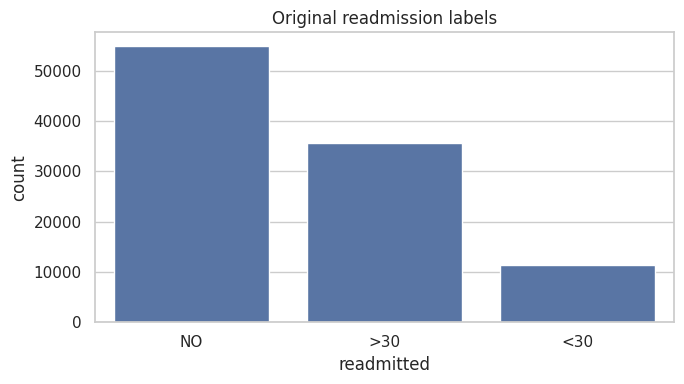

In [2]:
profile=pd.DataFrame({'dtype':raw.dtypes.astype(str),'missing':raw.isna().sum(),'missing_pct':(raw.isna().mean()*100).round(2),'n_unique':raw.nunique()}).sort_values('missing_pct',ascending=False)
profile.to_csv(ARTIFACTS/'data_profile.csv')
display(profile)
display(raw['readmitted'].value_counts(dropna=False).rename('count').to_frame())
plt.figure(figsize=(7,4)); sns.countplot(data=raw,x='readmitted',order=['NO','>30','<30']); plt.title('Original readmission labels'); plt.tight_layout(); plt.savefig(ARTIFACTS/'target_distribution.png',dpi=180); plt.show()

## 3. Data Preparation

The target is `<30` versus all other outcomes. Identifiers are excluded from predictors. Patient groups are used for the split so a patient cannot occur in both train and test sets.

In [3]:
y=(raw['readmitted'].astype(str)=='<30').astype(int)
groups=raw['patient_nbr']
drop=['readmitted','encounter_id','patient_nbr','weight','payer_code','medical_specialty']
X=raw.drop(columns=[c for c in drop if c in raw.columns]).copy()
if 'age' in X: X['age']=X['age'].astype('string')
split=GroupShuffleSplit(n_splits=1,test_size=.2,random_state=RANDOM_STATE)
train_idx,test_idx=next(split.split(X,y,groups=groups))
X_train,X_test=X.iloc[train_idx],X.iloc[test_idx]; y_train,y_test=y.iloc[train_idx],y.iloc[test_idx]
num=X_train.select_dtypes(include='number').columns.tolist(); cat=[c for c in X_train.columns if c not in num]
pre=ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat)])
print('train',X_train.shape,'test',X_test.shape,'train positive rate',round(y_train.mean(),4))

train (81613, 44) test (20153, 44) train positive rate 0.1128


## 4. Modeling

We compare an interpretable logistic regression with a class-weighted random forest.

In [4]:
models={'logistic_regression':LogisticRegression(max_iter=1000,class_weight='balanced',random_state=RANDOM_STATE),'random_forest':RandomForestClassifier(n_estimators=300,min_samples_leaf=5,class_weight='balanced_subsample',random_state=RANDOM_STATE,n_jobs=-1)}
fitted={}; rows=[]
for name,est in models.items():
    pipe=Pipeline([('preprocess',pre),('model',est)]); pipe.fit(X_train,y_train)
    p=pipe.predict_proba(X_test)[:,1]; pred=(p>=.5).astype(int); rep=classification_report(y_test,pred,output_dict=True,zero_division=0)
    rows.append({'model':name,'roc_auc':roc_auc_score(y_test,p),'pr_auc':average_precision_score(y_test,p),'precision':rep['1']['precision'],'recall':rep['1']['recall'],'f1':rep['1']['f1-score']}); fitted[name]=pipe
results=pd.DataFrame(rows).sort_values('pr_auc',ascending=False); results.to_csv(ARTIFACTS/'model_comparison.csv',index=False); display(results)

,model,roc_auc,pr_auc,precision,recall,f1
1,random_forest,0.659010,0.192847,0.188001,0.403533,0.256501
0,logistic_regression,0.630321,0.182255,0.153678,0.523477,0.237603


## 5. Evaluation

We evaluate ranking quality, classification errors, and threshold trade-offs. The final threshold should be selected with stakeholders based on intervention capacity and the cost of missed high-risk cases.

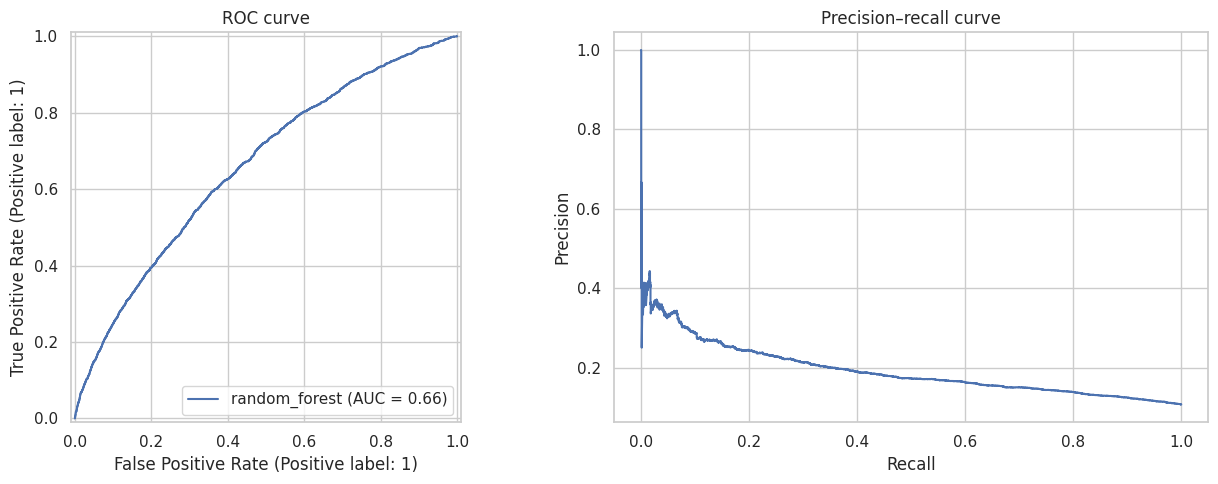

,precision,recall,f1-score,support
0,0.917418,0.791745,0.849961,18002.00000
1,0.188001,0.403533,0.256501,2151.00000
accuracy,0.750310,0.750310,0.750310,0.75031
macro avg,0.552709,0.597639,0.553231,20153.00000
weighted avg,0.839564,0.750310,0.786619,20153.00000


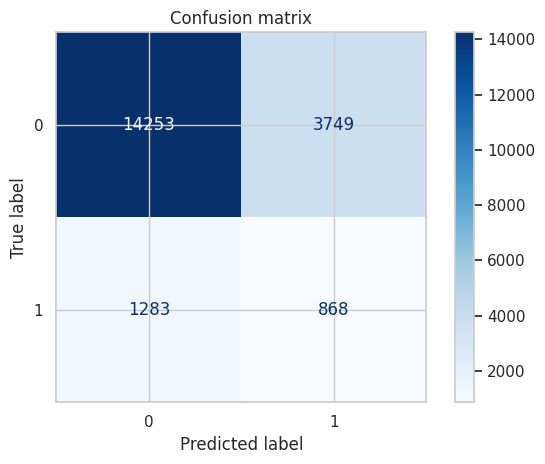

,threshold,precision,recall,f1,flagged_rate
0,0.10,0.106733,1.000000,0.192880,1.000000
1,0.15,0.106771,1.000000,0.192941,0.999653
2,0.20,0.106730,0.999070,0.192857,0.999107
3,0.25,0.107316,0.999070,0.193813,0.993649
4,0.30,0.110506,0.981404,0.198645,0.947899
5,0.35,0.119734,0.928870,0.212124,0.828016
6,0.40,0.134014,0.817294,0.230270,0.650920
7,0.45,0.156394,0.632264,0.250761,0.431499
8,0.50,0.188001,0.403533,0.256501,0.229097
9,0.55,0.236012,0.215714,0.225407,0.097554


In [5]:
best_name=results.iloc[0]['model']; best=fitted[best_name]; prob=best.predict_proba(X_test)[:,1]
fig,ax=plt.subplots(1,2,figsize=(13,5)); RocCurveDisplay.from_predictions(y_test,prob,name=best_name,ax=ax[0]); ax[0].set_title('ROC curve'); precision,recall,thresholds=precision_recall_curve(y_test,prob); ax[1].plot(recall,precision); ax[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall curve'); plt.tight_layout(); plt.savefig(ARTIFACTS/'evaluation_curves.png',dpi=180); plt.show()
pred=(prob>=.5).astype(int); report=pd.DataFrame(classification_report(y_test,pred,output_dict=True,zero_division=0)).T; report.to_csv(ARTIFACTS/'classification_report.csv'); display(report)
ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap='Blues'); plt.title('Confusion matrix'); plt.tight_layout(); plt.savefig(ARTIFACTS/'confusion_matrix.png',dpi=180); plt.show()
threshold_rows=[]
for t in np.arange(.10,.91,.05):
    z=(prob>=t).astype(int); r=classification_report(y_test,z,output_dict=True,zero_division=0)['1']; threshold_rows.append({'threshold':round(float(t),2),'precision':r['precision'],'recall':r['recall'],'f1':r['f1-score'],'flagged_rate':z.mean()})
thresholds_df=pd.DataFrame(threshold_rows); thresholds_df.to_csv(ARTIFACTS/'threshold_analysis.csv',index=False); display(thresholds_df)

In [6]:
joblib.dump(best,ARTIFACTS/'best_readmission_pipeline.joblib')
print('Saved artifacts to',ARTIFACTS)
print('Best model:',best_name)
print('Deployment note: human review, external validation, calibration monitoring, drift checks, and subgroup monitoring are required before any real-world use.')

Saved artifacts to /content/artifacts
Best model: random_forest
Deployment note: human review, external validation, calibration monitoring, drift checks, and subgroup monitoring are required before any real-world use.
